# Fruit Image Classification: Transfer Learning, Fine-Tuning and Streamlit Demo
**seKer AI | Project 04 | SKR-INT-CV-04**

Dataset: Fruits-360 (Kaggle `moltean/fruits`). Pipeline: data audit, EDA, model comparison (Custom CNN, MobileNetV2, ResNet50, EfficientNetB0), fine-tuning of the best backbone, before/after evaluation on the held-out test set, error analysis, and a Streamlit app.

**Kaggle setup:** Accelerator = GPU (T4 or P100), Internet = On (needed for ImageNet weights), and attach the dataset through *Add Input* (`moltean/fruits`).

Set `FAST_DEV = True` in the config cell for a quick smoke test (few images, 2 epochs).

## 1. Setup and configuration

In [2]:
import datetime
import hashlib
import json
import os
import random
import time
from concurrent.futures import ThreadPoolExecutor
from importlib.metadata import version
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from PIL import Image
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             precision_recall_fscore_support)
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.applications import efficientnet, mobilenet_v2, resnet50

SEED = 42
FAST_DEV = False

IMG_SIZE = 128
BATCH_SIZE = 64
VAL_FRACTION = 0.15
MAX_PER_CLASS = None
NUM_CLASSES_TO_USE = 70
SELECTED_CLASSES = None

EPOCHS_CUSTOM = 20
EPOCHS_HEAD = 12
EPOCHS_FT = 10
HEAD_LR = 1e-3
CUSTOM_LR = 1e-3
FT_LR = 1e-4
UNFREEZE_LAST = 40
PATIENCE = 3

MODELS_TO_COMPARE = ["custom_cnn", "mobilenetv2", "resnet50", "efficientnetb0"]
BEST_OVERRIDE = None

if FAST_DEV:
    MAX_PER_CLASS = 40
    EPOCHS_CUSTOM = EPOCHS_HEAD = EPOCHS_FT = 2

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

if tf.config.list_physical_devices("GPU"):
    keras.mixed_precision.set_global_policy("mixed_float16")

ARTIFACTS = Path("artifacts")
ARTIFACTS.mkdir(exist_ok=True)
AUTOTUNE = tf.data.AUTOTUNE
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})

print("TensorFlow", tf.__version__)
print("GPUs:", tf.config.list_physical_devices("GPU"))

TensorFlow 2.20.0
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


## 2. Dataset: sourcing and documentation

In [3]:
import kagglehub

DATASET_HANDLE = "moltean/fruits"
try:
    root = kagglehub.dataset_download(DATASET_HANDLE)
except Exception:
    kagglehub.login()
    root = kagglehub.dataset_download(DATASET_HANDLE)
ACCESS_DATE = datetime.date.today().isoformat()


def find_split_dirs(root, max_depth=5):
    found = {"training": [], "test": []}
    base = root.rstrip("/").count("/")
    for dirpath, dirnames, _ in os.walk(root):
        name = os.path.basename(dirpath).lower()
        if name in found and len(dirnames) > 20:
            found[name].append(dirpath)
            dirnames[:] = []
        elif dirpath.count("/") - base >= max_depth:
            dirnames[:] = []
    pick = lambda options: sorted(options, key=lambda p: ("100x100" not in p, p))[0]
    return pick(found["training"]), pick(found["test"])


print("root:", root)
sub_root = os.path.join(root, "fruits-360_100x100")
search_root = sub_root if os.path.isdir(sub_root) else root
print(sorted(os.listdir(search_root)))
TRAIN_DIR, TEST_DIR = find_split_dirs(search_root)
print(TRAIN_DIR)
print(TEST_DIR)

root: /kaggle/input/datasets/moltean/fruits
['fruits-360']
/kaggle/input/datasets/moltean/fruits/fruits-360_100x100/fruits-360/Training
/kaggle/input/datasets/moltean/fruits/fruits-360_100x100/fruits-360/Test


In [4]:
EXTS = {".jpg", ".jpeg", ".png"}

train_classes = sorted(d for d in os.listdir(TRAIN_DIR) if (Path(TRAIN_DIR) / d).is_dir())
test_classes = set(d for d in os.listdir(TEST_DIR) if (Path(TEST_DIR) / d).is_dir())
all_classes = [c for c in train_classes if c in test_classes]
if SELECTED_CLASSES:
    CLASSES = sorted(SELECTED_CLASSES)
elif NUM_CLASSES_TO_USE:
    picked = np.random.default_rng(SEED).choice(all_classes, size=NUM_CLASSES_TO_USE, replace=False)
    CLASSES = sorted(str(c) for c in picked)
else:
    CLASSES = all_classes
NUM_CLASSES = len(CLASSES)
class_to_idx = {c: i for i, c in enumerate(CLASSES)}


def list_split(split_dir):
    rows = []
    for c in CLASSES:
        for p in sorted((Path(split_dir) / c).iterdir()):
            if p.suffix.lower() in EXTS:
                rows.append((str(p), c))
    df = pd.DataFrame(rows, columns=["path", "label"])
    if MAX_PER_CLASS:
        df = df.groupby("label", group_keys=False).head(MAX_PER_CLASS).reset_index(drop=True)
    return df


train_all = list_split(TRAIN_DIR)
test_df = list_split(TEST_DIR)
print(f"classes used: {NUM_CLASSES} of {len(all_classes)} available")
print(CLASSES)
print(f"raw train images: {len(train_all)} | raw test images: {len(test_df)}")

classes used: 70 of 267 available
['Apple 22', 'Apple 6', 'Apple 8', 'Apple 9', 'Apple Crimson Snow 1', 'Apple Golden 1', 'Apple Golden 2', 'Apple Red 3', 'Banana 4', 'Banana Lady Finger 1', 'Banana Red 1', 'Blueberry 1', 'Cactus fruit green 1', 'Cherry 1', 'Chestnut 1', 'Corn Husk 1', 'Cucumber 10', 'Cucumber 11', 'Cucumber 13', 'Cucumber 7', 'Cucumber 9', 'Dates 1', 'Eggplant 1', 'Fig 1', 'Grape 1', 'Grape Blue 1', 'Grape Pink 1', 'Guava 1', 'Kumquats 1', 'Lemon Meyer 1', 'Mandarine 1', 'Mango Red 1', 'Mushroom champignon 4', 'Nectarine Flat 2', 'Nut 1', 'Nut Pecan 1', 'Onion Red 2', 'Onion White 1', 'Orange peeled 1', 'Peach 3', 'Peach 4', 'Peach 5', 'Pear 10', 'Pear 11', 'Pear 12', 'Pear 6', 'Pear Abate 1', 'Pear Monster 1', 'Pear Stone 1', 'Pepino 1', 'Pepper 2', 'Pepper Red 3', 'Pepper Yellow 1', 'Physalis 1', 'Physalis with Husk 1', 'Pistachio 1', 'Pitahaya Red 1', 'Plum 3', 'Pomelo Sweetie 1', 'Potato Red 1', 'Strawberry 1', 'Strawberry Wedge 1', 'Tamarillo 1', 'Tomato 8', 'Tom

## 3. Data integrity scan: corrupted, duplicated and mislabelled files

In [5]:
def inspect(path):
    try:
        with Image.open(path) as im:
            im.load()
        with open(path, "rb") as f:
            return hashlib.md5(f.read()).hexdigest(), None
    except Exception as e:
        return None, type(e).__name__


def scan(df):
    with ThreadPoolExecutor(16) as ex:
        res = list(ex.map(inspect, df["path"]))
    df = df.copy()
    df["hash"] = [r[0] for r in res]
    df["error"] = [r[1] for r in res]
    return df


train_all = scan(train_all)
test_df = scan(test_df)

report = {"raw_train": len(train_all), "raw_test": len(test_df)}
report["corrupted_train"] = int(train_all["error"].notna().sum())
report["corrupted_test"] = int(test_df["error"].notna().sum())
train_all = train_all[train_all["error"].isna()]
test_df = test_df[test_df["error"].isna()]

conflict_hashes = train_all.groupby("hash")["label"].nunique()
conflict_hashes = set(conflict_hashes[conflict_hashes > 1].index)
report["label_conflicts_removed"] = int(train_all["hash"].isin(conflict_hashes).sum())
train_all = train_all[~train_all["hash"].isin(conflict_hashes)]

report["duplicates_train"] = int(train_all.duplicated("hash").sum())
train_all = train_all.drop_duplicates("hash")
report["duplicates_test"] = int(test_df.duplicated("hash").sum())
test_df = test_df.drop_duplicates("hash")

leak = train_all["hash"].isin(set(test_df["hash"]))
report["train_test_overlap_removed"] = int(leak.sum())
train_all = train_all[~leak]

report["clean_train"] = len(train_all)
report["clean_test"] = len(test_df)
pd.Series(report, name="count").to_frame()

,count
raw_train,38091
raw_test,12703
corrupted_train,0
corrupted_test,0
label_conflicts_removed,0
duplicates_train,0
duplicates_test,0
train_test_overlap_removed,0
clean_train,38091
clean_test,12703


In [6]:
train_all["y"] = train_all["label"].map(class_to_idx)
test_df["y"] = test_df["label"].map(class_to_idx)

train_df, val_df = train_test_split(
    train_all, test_size=VAL_FRACTION, stratify=train_all["y"], random_state=SEED
)
train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

total = len(train_df) + len(val_df) + len(test_df)
print(f"train {len(train_df)} ({len(train_df)/total:.1%}) | val {len(val_df)} ({len(val_df)/total:.1%}) | test {len(test_df)} ({len(test_df)/total:.1%})")

dataset_card = {
    "name": "Fruits-360 (Kaggle: moltean/fruits)",
    "source_url": "https://www.kaggle.com/datasets/moltean/fruits",
    "licence": "CC BY-SA 4.0 (confirm on the dataset page)",
    "total_images_after_cleaning": total,
    "num_classes": NUM_CLASSES,
    "accessed": ACCESS_DATE,
    "split": f"train/val from the official Training folder (stratified, seed={SEED}); test = official Test folder",
}
print(json.dumps(dataset_card, indent=2))
print(CLASSES)

train 32377 (63.7%) | val 5714 (11.2%) | test 12703 (25.0%)
{
  "name": "Fruits-360 (Kaggle: moltean/fruits)",
  "source_url": "https://www.kaggle.com/datasets/moltean/fruits",
  "licence": "CC BY-SA 4.0 (confirm on the dataset page)",
  "total_images_after_cleaning": 50794,
  "num_classes": 70,
  "accessed": "2026-10-14",
  "split": "train/val from the official Training folder (stratified, seed=42); test = official Test folder"
}
['Apple 22', 'Apple 6', 'Apple 8', 'Apple 9', 'Apple Crimson Snow 1', 'Apple Golden 1', 'Apple Golden 2', 'Apple Red 3', 'Banana 4', 'Banana Lady Finger 1', 'Banana Red 1', 'Blueberry 1', 'Cactus fruit green 1', 'Cherry 1', 'Chestnut 1', 'Corn Husk 1', 'Cucumber 10', 'Cucumber 11', 'Cucumber 13', 'Cucumber 7', 'Cucumber 9', 'Dates 1', 'Eggplant 1', 'Fig 1', 'Grape 1', 'Grape Blue 1', 'Grape Pink 1', 'Guava 1', 'Kumquats 1', 'Lemon Meyer 1', 'Mandarine 1', 'Mango Red 1', 'Mushroom champignon 4', 'Nectarine Flat 2', 'Nut 1', 'Nut Pecan 1', 'Onion Red 2', 'Onion

**Split note.** The test set is the official `Test` folder and is evaluated once, in section 12. Fruits-360 images come from turntable captures, so near-duplicate frames inside `Training` can make the random validation split optimistic. Treat the test numbers as the honest ones.

## 4. Exploratory image analysis

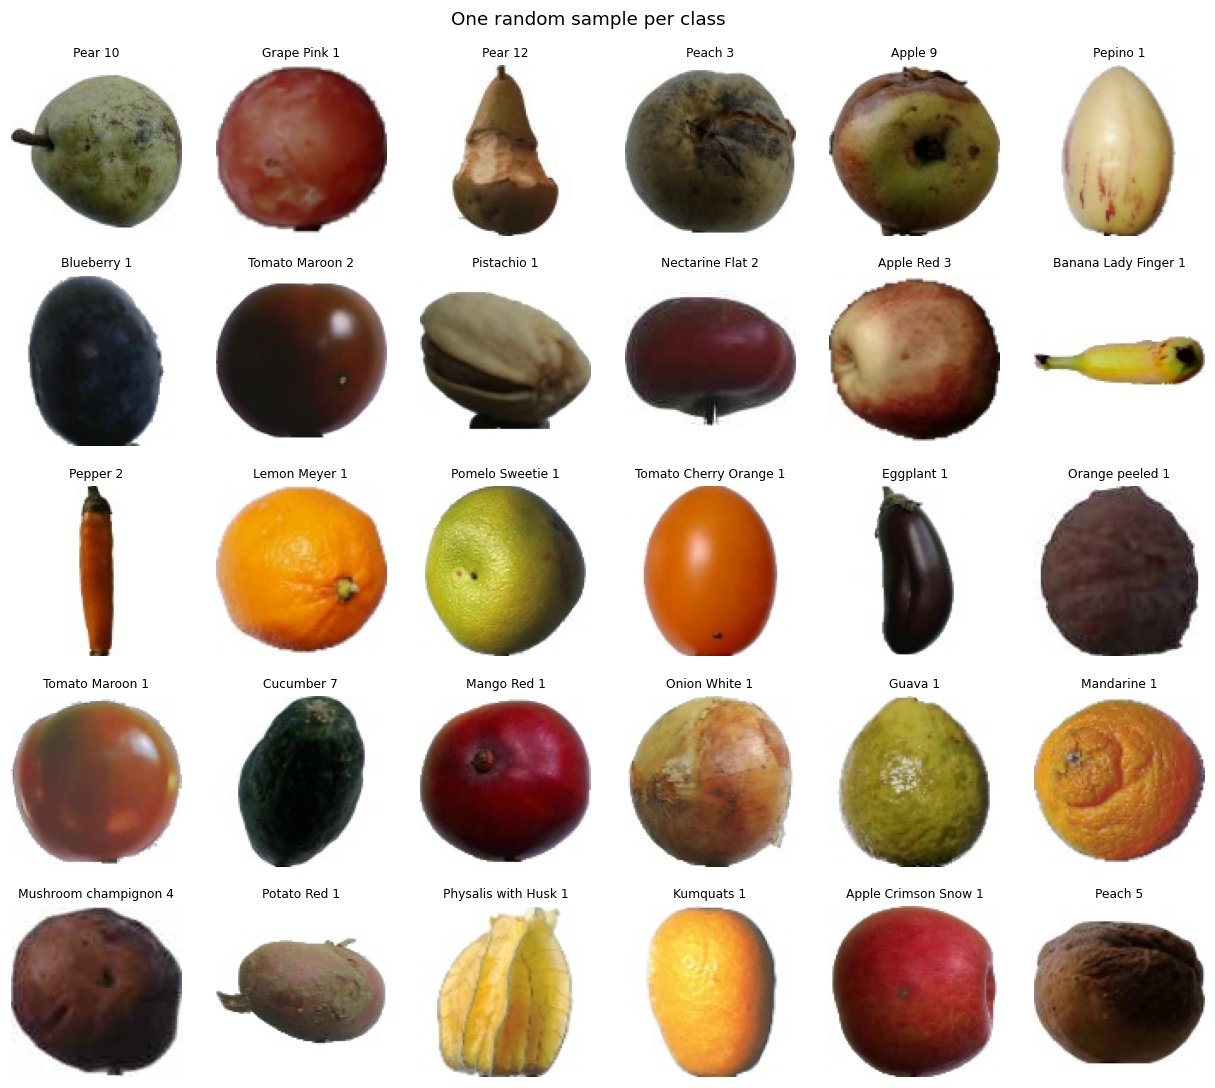

In [7]:
rng = np.random.default_rng(SEED)
sample_classes = rng.choice(CLASSES, size=min(30, NUM_CLASSES), replace=False)
fig, axes = plt.subplots(5, 6, figsize=(14, 12))
for ax in axes.ravel():
    ax.axis("off")
for ax, c in zip(axes.ravel(), sample_classes):
    p = train_df[train_df["label"] == c].sample(1, random_state=SEED)["path"].iloc[0]
    ax.imshow(Image.open(p))
    ax.set_title(c, fontsize=8)
plt.suptitle("One random sample per class", y=0.92)
plt.show()

**Observation:** 

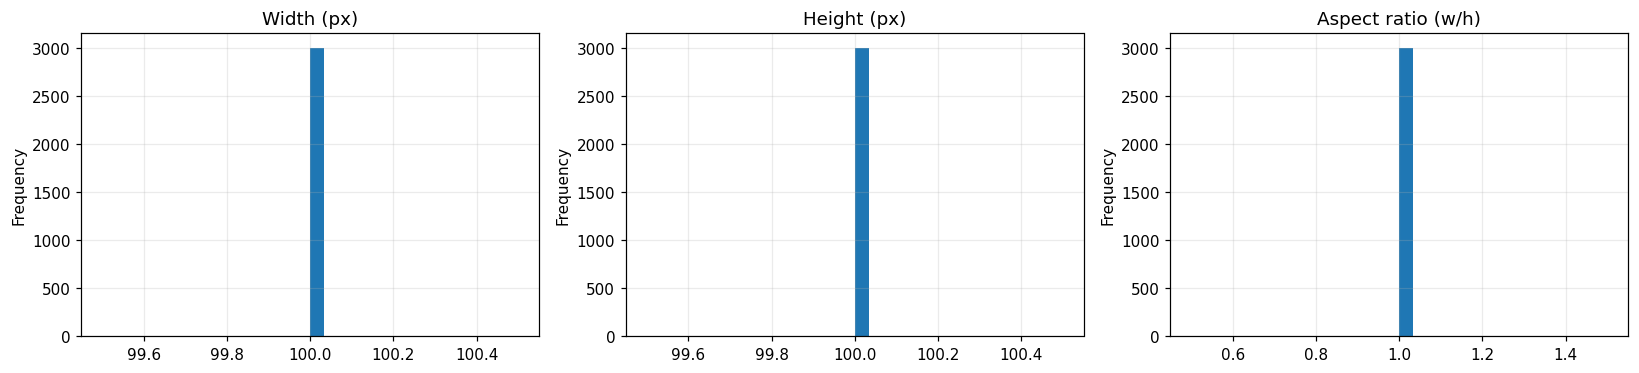

      width  height  aspect
min   100.0   100.0     1.0
max   100.0   100.0     1.0
mean  100.0   100.0     1.0


In [8]:
sizes = [Image.open(p).size for p in train_df["path"].sample(min(3000, len(train_df)), random_state=SEED)]
dims = pd.DataFrame(sizes, columns=["width", "height"])
dims["aspect"] = dims["width"] / dims["height"]

fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
dims["width"].plot.hist(ax=axes[0], bins=30, title="Width (px)")
dims["height"].plot.hist(ax=axes[1], bins=30, title="Height (px)")
dims["aspect"].plot.hist(ax=axes[2], bins=30, title="Aspect ratio (w/h)")
plt.tight_layout()
plt.show()
print(dims.describe().loc[["min", "max", "mean"]])

**Observation:** 

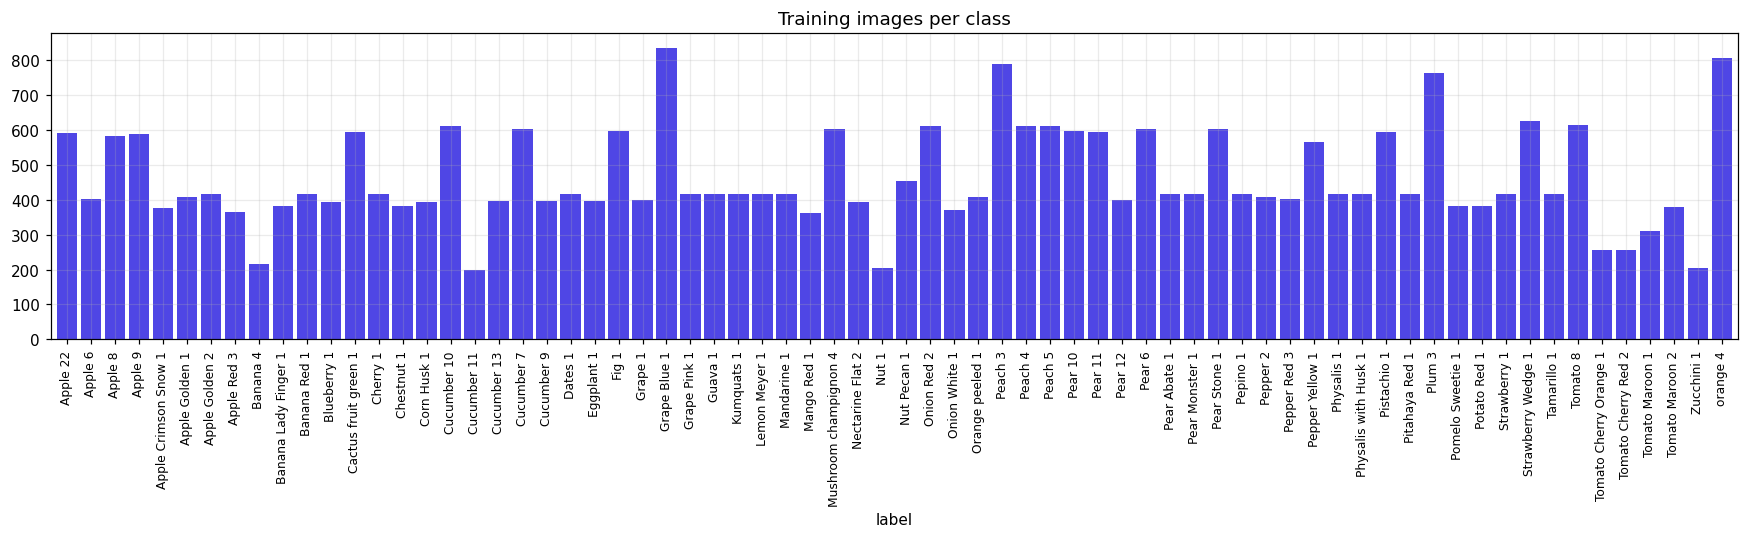

max/min class ratio (train): 4.20
count     70.0
mean     462.5
std      139.6
min      199.0
25%      393.2
50%      416.0
75%      593.8
max      836.0
Name: train, dtype: float64


In [9]:
counts = pd.DataFrame({
    "train": train_df["label"].value_counts(),
    "val": val_df["label"].value_counts(),
    "test": test_df["label"].value_counts(),
}).reindex(CLASSES).fillna(0).astype(int)

fig, ax = plt.subplots(figsize=(16, 5))
counts["train"].plot.bar(ax=ax, width=0.85, color="#4f46e5")
ax.set_title("Training images per class")
ax.tick_params(axis="x", labelsize=8)
plt.tight_layout()
plt.show()

print(f"max/min class ratio (train): {counts['train'].max() / counts['train'].min():.2f}")
print(counts["train"].describe().round(1))

**Observation:** 

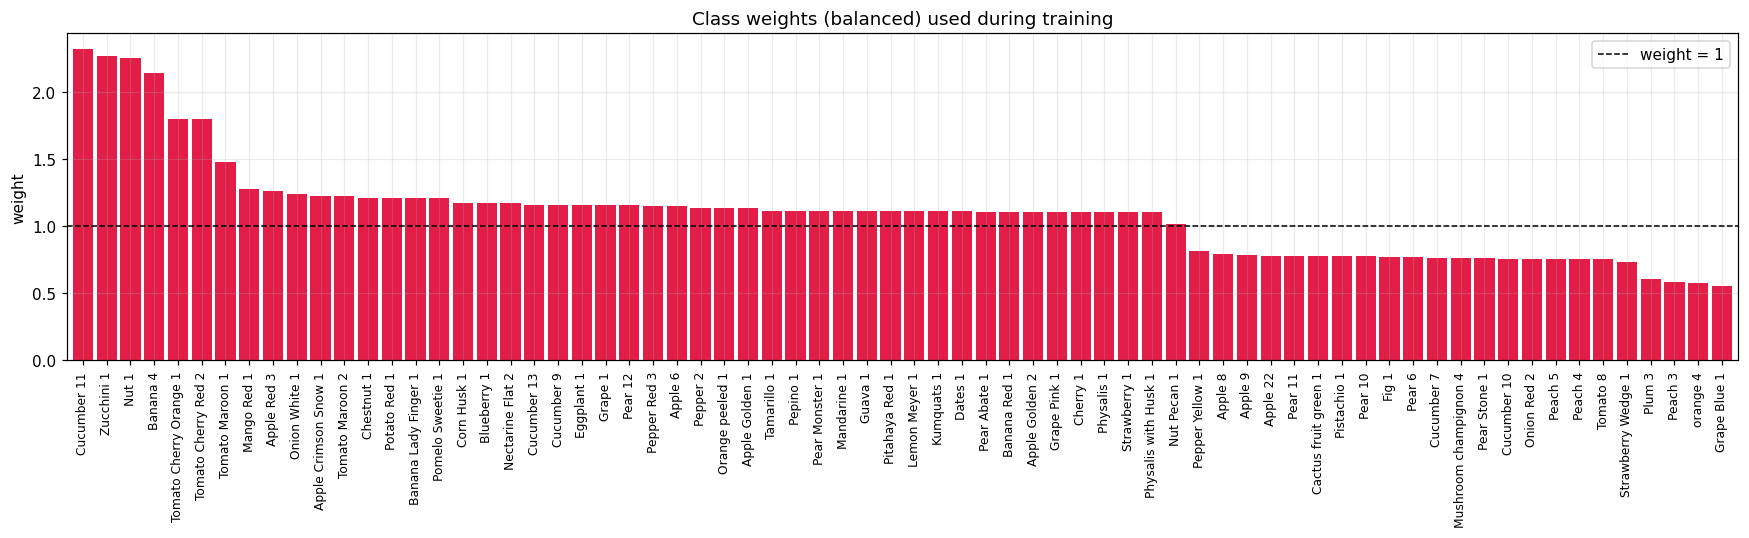

{'Cucumber 11': 2.324, 'Zucchini 1': 2.267, 'Nut 1': 2.256, 'Banana 4': 2.141, 'Tomato Cherry Orange 1': 1.8}
{'Strawberry Wedge 1': 0.738, 'Plum 3': 0.605, 'Peach 3': 0.587, 'orange 4': 0.574, 'Grape Blue 1': 0.553}


In [10]:
weights = compute_class_weight("balanced", classes=np.arange(NUM_CLASSES), y=train_df["y"].values)
class_weights = dict(enumerate(weights))
cw = pd.Series(weights, index=CLASSES).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(16, 5))
cw.plot.bar(ax=ax, width=0.85, color="#e11d48")
ax.axhline(1.0, color="black", linestyle="--", linewidth=1, label="weight = 1")
ax.set_title("Class weights (balanced) used during training")
ax.set_ylabel("weight")
ax.tick_params(axis="x", labelsize=8)
ax.legend()
plt.tight_layout()
plt.show()

print(cw.head(5).round(3).to_dict())
print(cw.tail(5).round(3).to_dict())

**Observation:** 

## 5. Input pipeline, preprocessing and augmentation

In [11]:
BACKBONES = {
    "mobilenetv2": (mobilenet_v2.MobileNetV2, mobilenet_v2.preprocess_input),
    "resnet50": (resnet50.ResNet50, resnet50.preprocess_input),
    "efficientnetb0": (efficientnet.EfficientNetB0, efficientnet.preprocess_input),
}
PREPROCESS = {name: fn for name, (_, fn) in BACKBONES.items()}
PREPROCESS["custom_cnn"] = lambda x: x / 255.0

augment = keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.1, fill_mode="nearest"),
    layers.RandomZoom(0.15, fill_mode="nearest"),
    layers.RandomTranslation(0.1, 0.1, fill_mode="nearest"),
    layers.RandomBrightness(0.2, value_range=(0, 255)),
    layers.RandomContrast(0.2),
], name="augment")


def load_img(path, label):
    img = tf.io.read_file(path)
    img = tf.image.decode_image(img, channels=3, expand_animations=False)
    img.set_shape([None, None, 3])
    img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))
    return tf.cast(tf.round(img), tf.uint8), label


_decoded = {}


def decoded_ds(df):
    key = id(df)
    if key not in _decoded:
        ds = tf.data.Dataset.from_tensor_slices((df["path"].values, df["y"].values))
        _decoded[key] = ds.map(load_img, num_parallel_calls=AUTOTUNE).cache()
    return _decoded[key]


def make_ds(df, preprocess, training):
    ds = decoded_ds(df)
    if training:
        ds = ds.shuffle(min(len(df), 8192), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.batch(BATCH_SIZE)

    def prep(x, y):
        x = tf.cast(x, tf.float32)
        if training:
            x = augment(x, training=True)
        return preprocess(x), y

    return ds.map(prep, num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)

I0000 00:00:1791952079.937811      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1791952079.942089      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


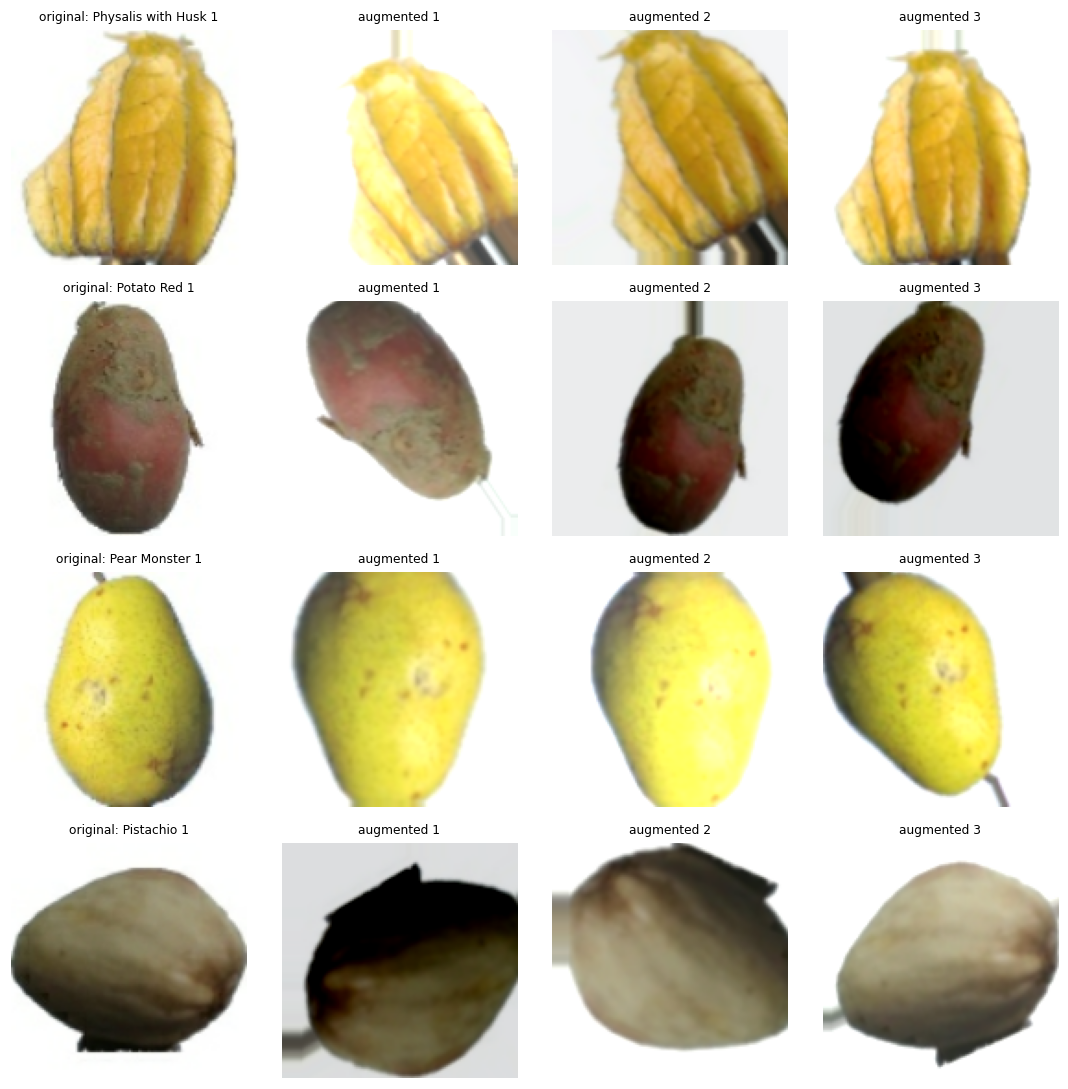

In [12]:
sample = train_df.sample(4, random_state=SEED)
fig, axes = plt.subplots(4, 4, figsize=(10, 10))
for i, (p, lbl) in enumerate(zip(sample["path"], sample["label"])):
    img, _ = load_img(p, 0)
    img = tf.cast(img, tf.float32)
    axes[i, 0].imshow(img.numpy().astype("uint8"))
    axes[i, 0].set_title(f"original: {lbl}", fontsize=8)
    for j in range(1, 4):
        aug = augment(tf.expand_dims(img, 0), training=True)[0].numpy()
        axes[i, j].imshow(np.clip(aug, 0, 255).astype("uint8"))
        axes[i, j].set_title(f"augmented {j}", fontsize=8)
for ax in axes.ravel():
    ax.axis("off")
plt.tight_layout()
plt.show()

**Observation:** 

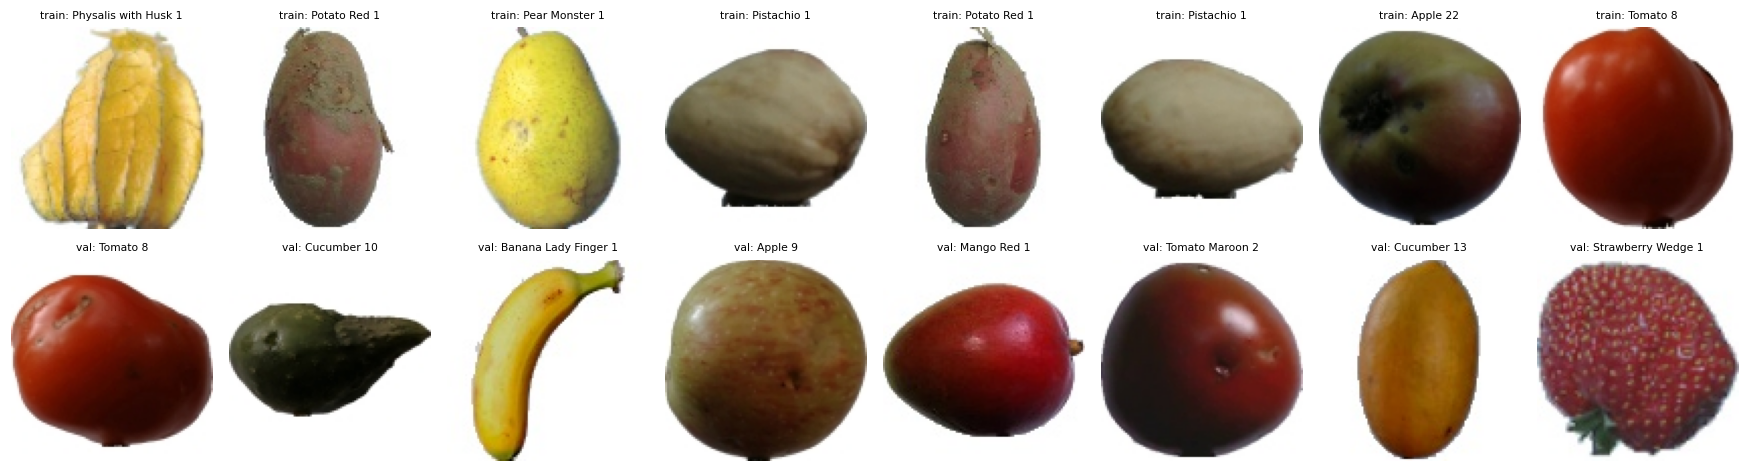

max |train - val| class proportion gap: 0.00010


In [13]:
fig, axes = plt.subplots(2, 8, figsize=(16, 4.5))
for row, (name, df) in enumerate((("train", train_df), ("val", val_df))):
    for ax, (_, r) in zip(axes[row], df.sample(8, random_state=SEED).iterrows()):
        ax.imshow(Image.open(r["path"]))
        ax.set_title(f"{name}: {r['label']}", fontsize=7)
        ax.axis("off")
plt.tight_layout()
plt.show()

prop = pd.DataFrame({
    "train": train_df["y"].value_counts(normalize=True),
    "val": val_df["y"].value_counts(normalize=True),
}).fillna(0)
print(f"max |train - val| class proportion gap: {(prop['train'] - prop['val']).abs().max():.5f}")

**Observation:** 

## 6. Model definitions

In [14]:
def build_custom_cnn(n_classes):
    inp = keras.Input((IMG_SIZE, IMG_SIZE, 3))
    x = inp
    for filters in (32, 64, 128, 256):
        for _ in range(2):
            x = layers.Conv2D(filters, 3, padding="same", use_bias=False)(x)
            x = layers.BatchNormalization()(x)
            x = layers.ReLU()(x)
        x = layers.MaxPooling2D()(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.4)(x)
    out = layers.Dense(n_classes, activation="softmax", dtype="float32")(x)
    return keras.Model(inp, out, name="custom_cnn"), None


def build_transfer(name, n_classes):
    ctor, _ = BACKBONES[name]
    base = ctor(include_top=False, weights="imagenet", input_shape=(IMG_SIZE, IMG_SIZE, 3))
    base.trainable = False
    inp = keras.Input((IMG_SIZE, IMG_SIZE, 3))
    x = base(inp, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(256, activation="relu")(x)
    x = layers.Dropout(0.3)(x)
    out = layers.Dense(n_classes, activation="softmax", dtype="float32")(x)
    return keras.Model(inp, out, name=name), base


def build(name):
    return build_custom_cnn(NUM_CLASSES) if name == "custom_cnn" else build_transfer(name, NUM_CLASSES)


def fit(model, train_ds, val_ds, epochs, lr, tag):
    model.compile(
        optimizer=keras.optimizers.Adam(lr),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )
    callbacks = [
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE, restore_best_weights=True),
        keras.callbacks.ModelCheckpoint(
            str(ARTIFACTS / f"{tag}.weights.h5"), monitor="val_loss",
            save_best_only=True, save_weights_only=True),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.3, patience=2, min_lr=1e-7),
    ]
    start = time.time()
    hist = model.fit(train_ds, validation_data=val_ds, epochs=epochs,
                     class_weight=class_weights, callbacks=callbacks, verbose=2)
    return hist.history, time.time() - start


def summarize(y_true, y_pred):
    p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
    wf = precision_recall_fscore_support(y_true, y_pred, average="weighted", zero_division=0)[2]
    return {"accuracy": accuracy_score(y_true, y_pred), "precision": p, "recall": r,
            "f1": f, "weighted_f1": wf}

## 7. Train and compare all models (head training, validation set)

In [15]:
runs = {}
for name in MODELS_TO_COMPARE:
    keras.backend.clear_session()
    model, base = build(name)
    pre = PREPROCESS[name]
    train_ds = make_ds(train_df, pre, True)
    val_ds = make_ds(val_df, pre, False)
    is_custom = name == "custom_cnn"
    print(f"\n=== {name} | params {model.count_params():,} ===")
    hist, secs = fit(model, train_ds, val_ds,
                     EPOCHS_CUSTOM if is_custom else EPOCHS_HEAD,
                     CUSTOM_LR if is_custom else HEAD_LR, f"{name}_head")
    val_pred = model.predict(val_ds, verbose=0).argmax(1)
    runs[name] = {"history": hist, "seconds": secs, "params": model.count_params(),
                  "val": summarize(val_df["y"].values, val_pred)}

comparison = pd.DataFrame({
    n: {**r["val"], "params_M": r["params"] / 1e6, "minutes": r["seconds"] / 60,
        "epochs_run": len(r["history"]["loss"])}
    for n, r in runs.items()
}).T
comparison.round(4)


=== custom_cnn | params 1,193,126 ===
Epoch 1/20


2026-10-14 04:28:26.595392: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-14 04:28:26.757928: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-14 04:28:28.752314: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-14 04:28:29.063476: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
I0000 00:00:1791952116.263444     120 device_compiler.h:196]

506/506 - 156s - 308ms/step - accuracy: 0.5361 - loss: 1.5097 - val_accuracy: 0.5718 - val_loss: 1.2245 - learning_rate: 0.0010
Epoch 2/20
506/506 - 108s - 214ms/step - accuracy: 0.8087 - loss: 0.5787 - val_accuracy: 0.7189 - val_loss: 0.7928 - learning_rate: 0.0010
Epoch 3/20
506/506 - 110s - 217ms/step - accuracy: 0.8786 - loss: 0.3683 - val_accuracy: 0.9001 - val_loss: 0.3057 - learning_rate: 0.0010
Epoch 4/20
506/506 - 109s - 216ms/step - accuracy: 0.9196 - loss: 0.2398 - val_accuracy: 0.5648 - val_loss: 2.0796 - learning_rate: 0.0010
Epoch 5/20
506/506 - 110s - 217ms/step - accuracy: 0.9312 - loss: 0.2016 - val_accuracy: 0.8089 - val_loss: 0.6223 - learning_rate: 0.0010
Epoch 6/20
506/506 - 109s - 215ms/step - accuracy: 0.9707 - loss: 0.0955 - val_accuracy: 0.9912 - val_loss: 0.0355 - learning_rate: 3.0000e-04
Epoch 7/20
506/506 - 109s - 216ms/step - accuracy: 0.9784 - loss: 0.0757 - val_accuracy: 0.9961 - val_loss: 0.0160 - learning_rate: 3.0000e-04
Epoch 8/20
506/506 - 110s - 21

2026-10-14 04:47:26.314405: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-14 04:47:26.451366: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-14 04:49:19.575277: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-14 04:49:19.716783: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-14 04:49:19.853838: E external/local_xla/xla/stream_

506/506 - 154s - 305ms/step - accuracy: 0.8066 - loss: 0.6645 - val_accuracy: 0.9585 - val_loss: 0.1390 - learning_rate: 0.0010
Epoch 2/12
506/506 - 106s - 209ms/step - accuracy: 0.9378 - loss: 0.1782 - val_accuracy: 0.9636 - val_loss: 0.1056 - learning_rate: 0.0010
Epoch 3/12
506/506 - 105s - 207ms/step - accuracy: 0.9547 - loss: 0.1236 - val_accuracy: 0.9865 - val_loss: 0.0496 - learning_rate: 0.0010
Epoch 4/12
506/506 - 105s - 207ms/step - accuracy: 0.9602 - loss: 0.1088 - val_accuracy: 0.9830 - val_loss: 0.0523 - learning_rate: 0.0010
Epoch 5/12
506/506 - 104s - 206ms/step - accuracy: 0.9667 - loss: 0.0905 - val_accuracy: 0.9778 - val_loss: 0.0613 - learning_rate: 0.0010
Epoch 6/12
506/506 - 105s - 208ms/step - accuracy: 0.9790 - loss: 0.0560 - val_accuracy: 0.9916 - val_loss: 0.0302 - learning_rate: 3.0000e-04
Epoch 7/12
506/506 - 106s - 209ms/step - accuracy: 0.9802 - loss: 0.0537 - val_accuracy: 0.9912 - val_loss: 0.0273 - learning_rate: 3.0000e-04
Epoch 8/12
506/506 - 106s - 21

2026-10-14 05:32:47.625005: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-14 05:32:47.762185: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-14 05:32:48.112441: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-14 05:32:48.255481: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-14 05:32:49.099459: E external/local_xla/xla/stream_

506/506 - 155s - 307ms/step - accuracy: 0.8421 - loss: 0.5782 - val_accuracy: 0.9876 - val_loss: 0.0762 - learning_rate: 0.0010
Epoch 2/12
506/506 - 101s - 199ms/step - accuracy: 0.9586 - loss: 0.1263 - val_accuracy: 0.9895 - val_loss: 0.0449 - learning_rate: 0.0010
Epoch 3/12
506/506 - 100s - 198ms/step - accuracy: 0.9717 - loss: 0.0830 - val_accuracy: 0.9953 - val_loss: 0.0249 - learning_rate: 0.0010
Epoch 4/12
506/506 - 101s - 199ms/step - accuracy: 0.9770 - loss: 0.0673 - val_accuracy: 0.9965 - val_loss: 0.0174 - learning_rate: 0.0010
Epoch 5/12
506/506 - 101s - 200ms/step - accuracy: 0.9816 - loss: 0.0541 - val_accuracy: 0.9939 - val_loss: 0.0196 - learning_rate: 0.0010
Epoch 6/12
506/506 - 102s - 201ms/step - accuracy: 0.9821 - loss: 0.0507 - val_accuracy: 0.9975 - val_loss: 0.0091 - learning_rate: 0.0010
Epoch 7/12
506/506 - 97s - 191ms/step - accuracy: 0.9828 - loss: 0.0474 - val_accuracy: 0.9972 - val_loss: 0.0106 - learning_rate: 0.0010
Epoch 8/12
506/506 - 102s - 201ms/step 

,accuracy,precision,recall,f1,weighted_f1,params_M,minutes,epochs_run
custom_cnn,0.9961,0.9968,0.9966,0.9966,0.9961,1.1931,18.8763,10.0
mobilenetv2,0.9954,0.9960,0.9964,0.9961,0.9955,2.6039,21.8350,12.0
resnet50,0.9977,0.9983,0.9983,0.9982,0.9977,24.1302,23.0370,12.0
efficientnetb0,0.9995,0.9994,0.9992,0.9993,0.9995,4.3955,21.0453,12.0


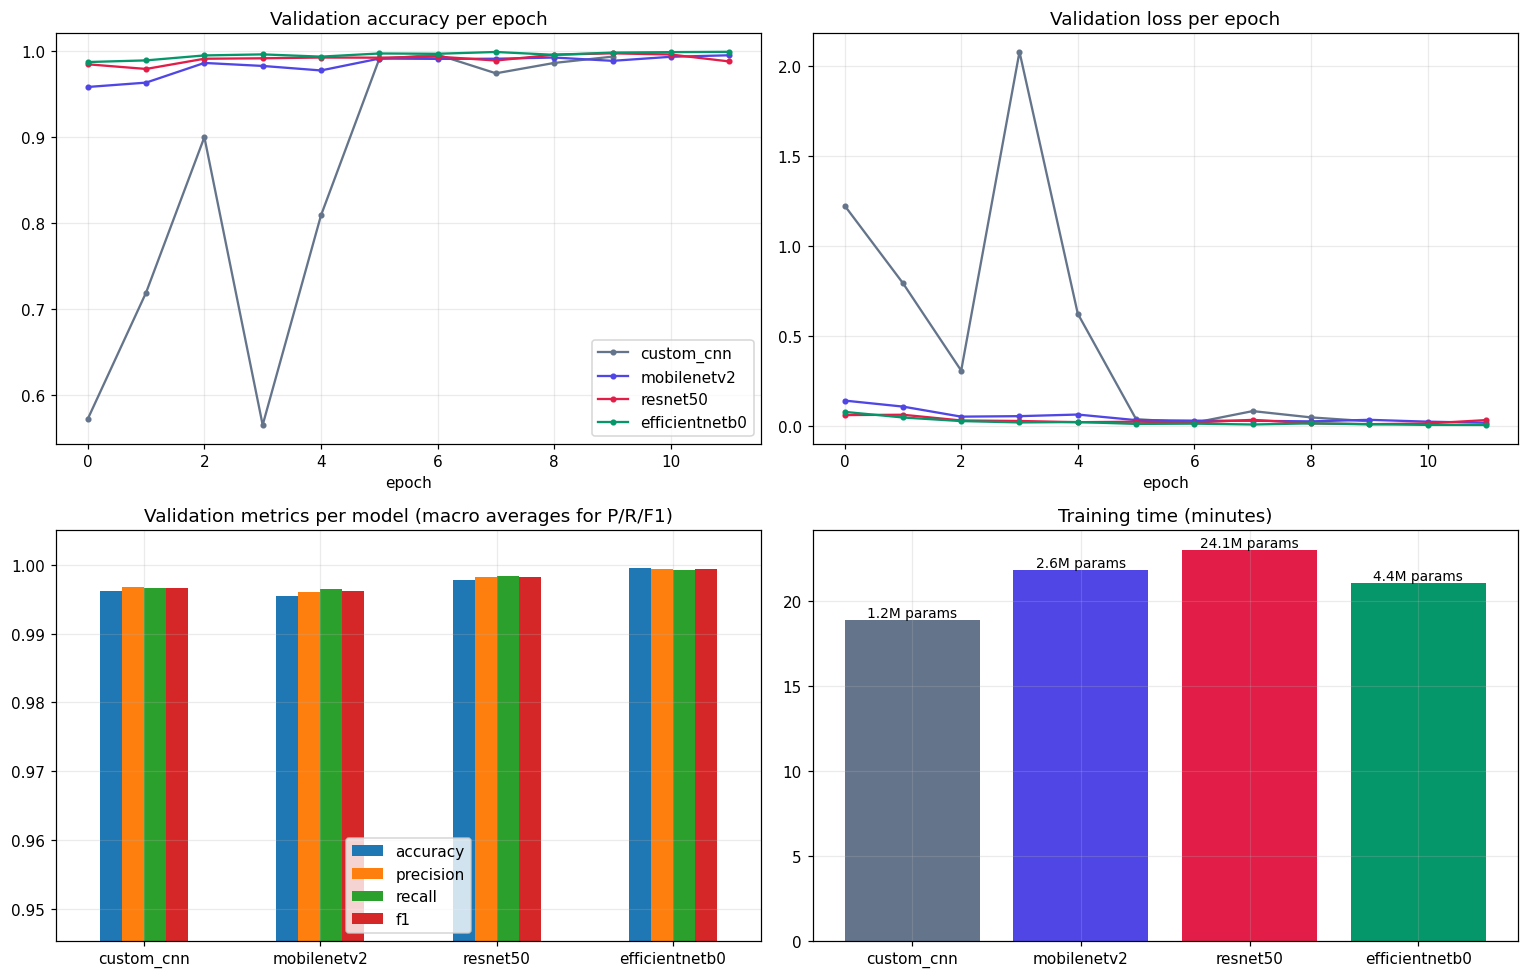

In [16]:
colors = dict(zip(MODELS_TO_COMPARE, ["#64748b", "#4f46e5", "#e11d48", "#059669"]))
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for n, r in runs.items():
    axes[0, 0].plot(r["history"]["val_accuracy"], label=n, color=colors[n], marker="o", markersize=3)
    axes[0, 1].plot(r["history"]["val_loss"], label=n, color=colors[n], marker="o", markersize=3)
axes[0, 0].set(title="Validation accuracy per epoch", xlabel="epoch")
axes[0, 1].set(title="Validation loss per epoch", xlabel="epoch")
axes[0, 0].legend()

comparison[["accuracy", "precision", "recall", "f1"]].plot.bar(ax=axes[1, 0], rot=0)
axes[1, 0].set(title="Validation metrics per model (macro averages for P/R/F1)", ylim=(max(0, comparison[["accuracy", "f1"]].min().min() - 0.05), 1.005))

bars = axes[1, 1].bar(comparison.index, comparison["minutes"], color=[colors[n] for n in comparison.index])
for b, params in zip(bars, comparison["params_M"]):
    axes[1, 1].annotate(f"{params:.1f}M params", (b.get_x() + b.get_width() / 2, b.get_height()),
                        ha="center", va="bottom", fontsize=9)
axes[1, 1].set(title="Training time (minutes)")
plt.tight_layout()
plt.show()

**Observation:** 

In [17]:
candidates = comparison.drop(index="custom_cnn", errors="ignore")
BEST = BEST_OVERRIDE or candidates["f1"].idxmax()
print("Backbone selected for fine-tuning:", BEST)

Backbone selected for fine-tuning: efficientnetb0


**Architecture justification.** What was considered: Custom CNN, MobileNetV2, ResNet50, EfficientNetB0. Selection used validation macro-F1 with training time and parameter count as secondary evidence (table above). Fill in what was rejected and why.

## 8. Fine-tuning the selected backbone

In [18]:
keras.backend.clear_session()
model, base = build(BEST)
model.load_weights(str(ARTIFACTS / f"{BEST}_head.weights.h5"))

pre = PREPROCESS[BEST]
train_ds = make_ds(train_df, pre, True)
val_ds = make_ds(val_df, pre, False)

base.trainable = True
for layer in base.layers[:-UNFREEZE_LAST]:
    layer.trainable = False
for layer in base.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

trainable = sum(int(np.prod(w.shape)) for w in model.trainable_weights)
print(f"trainable parameters during fine-tuning: {trainable:,}")

ft_hist, ft_secs = fit(model, train_ds, val_ds, EPOCHS_FT, FT_LR, f"{BEST}_ft")
print(f"fine-tuning time: {ft_secs / 60:.1f} min")

trainable parameters during fine-tuning: 2,383,446
Epoch 1/10
506/506 - 152s - 301ms/step - accuracy: 0.9914 - loss: 0.0243 - val_accuracy: 0.9984 - val_loss: 0.0046 - learning_rate: 1.0000e-04
Epoch 2/10
506/506 - 100s - 198ms/step - accuracy: 0.9935 - loss: 0.0174 - val_accuracy: 0.9984 - val_loss: 0.0037 - learning_rate: 1.0000e-04
Epoch 3/10
506/506 - 99s - 196ms/step - accuracy: 0.9943 - loss: 0.0175 - val_accuracy: 0.9984 - val_loss: 0.0046 - learning_rate: 1.0000e-04
Epoch 4/10
506/506 - 100s - 197ms/step - accuracy: 0.9953 - loss: 0.0123 - val_accuracy: 0.9995 - val_loss: 0.0030 - learning_rate: 1.0000e-04
Epoch 5/10
506/506 - 100s - 198ms/step - accuracy: 0.9964 - loss: 0.0100 - val_accuracy: 0.9988 - val_loss: 0.0032 - learning_rate: 1.0000e-04
Epoch 6/10
506/506 - 101s - 199ms/step - accuracy: 0.9968 - loss: 0.0084 - val_accuracy: 0.9989 - val_loss: 0.0033 - learning_rate: 1.0000e-04
Epoch 7/10
506/506 - 102s - 202ms/step - accuracy: 0.9985 - loss: 0.0040 - val_accuracy: 0.9

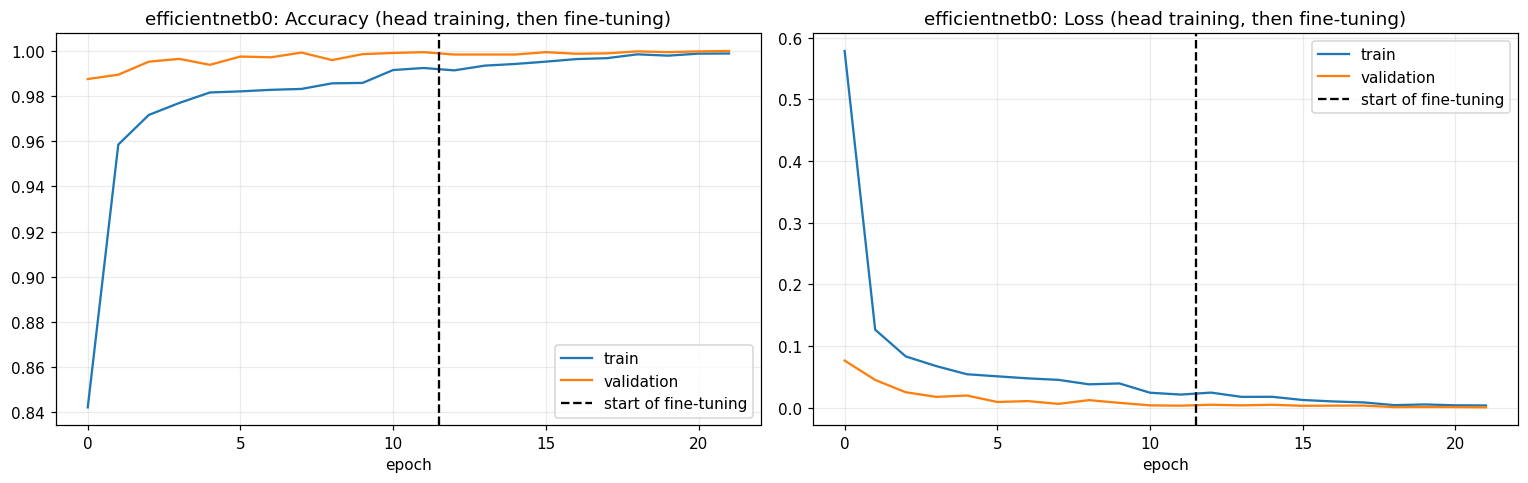

In [19]:
head_hist = runs[BEST]["history"]
n_head = len(head_hist["loss"])
curve = lambda key: head_hist[key] + ft_hist[key]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, (train_key, val_key, title) in zip(axes, (
        ("accuracy", "val_accuracy", "Accuracy"), ("loss", "val_loss", "Loss"))):
    ax.plot(curve(train_key), label="train")
    ax.plot(curve(val_key), label="validation")
    ax.axvline(n_head - 0.5, color="black", linestyle="--", label="start of fine-tuning")
    ax.set(title=f"{BEST}: {title} (head training, then fine-tuning)", xlabel="epoch")
    ax.legend()
plt.tight_layout()
plt.show()

**Observation:** 

## 9. Final evaluation on the held-out test set (before vs after fine-tuning)

In [20]:
def predict_stage(weights_file):
    keras.backend.clear_session()
    m, _ = build(BEST)
    m.load_weights(str(weights_file))
    out = {}
    for split, df in (("val", val_df), ("test", test_df)):
        probs = m.predict(make_ds(df, pre, False), verbose=0)
        out[split] = {"y_true": df["y"].values, "probs": probs, "y_pred": probs.argmax(1)}
    return m, out


_, before = predict_stage(ARTIFACTS / f"{BEST}_head.weights.h5")
final_model, after = predict_stage(ARTIFACTS / f"{BEST}_ft.weights.h5")

table = pd.DataFrame({
    f"{split}_{stage}": summarize(res[split]["y_true"], res[split]["y_pred"])
    for split in ("val", "test")
    for stage, res in (("before", before), ("after", after))
})
table.round(4)

2026-10-14 06:12:17.765164: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-14 06:12:17.899839: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-14 06:12:18.237919: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-14 06:12:18.381895: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-14 06:12:19.246968: E external/local_xla/xla/stream_

,val_before,val_after,test_before,test_after
accuracy,0.9995,1.0,0.9925,0.9946
precision,0.9994,1.0,0.9939,0.9955
recall,0.9992,1.0,0.9910,0.9937
f1,0.9993,1.0,0.9920,0.9942
weighted_f1,0.9995,1.0,0.9922,0.9943


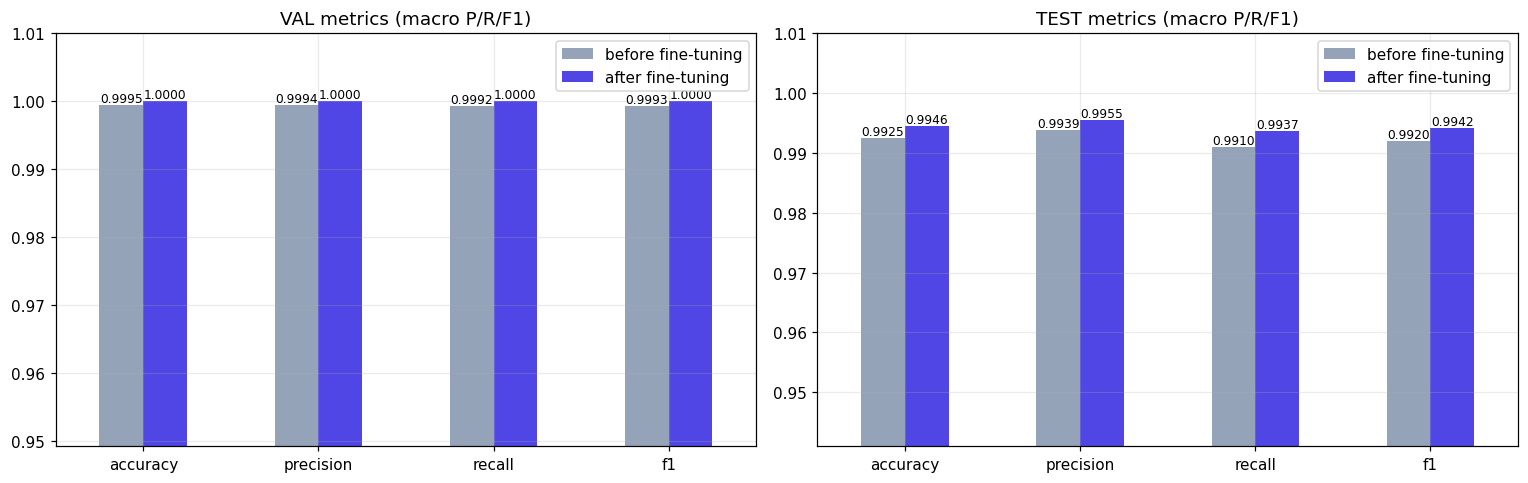

In [21]:
metric_names = ["accuracy", "precision", "recall", "f1"]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, split in zip(axes, ("val", "test")):
    df_plot = table[[f"{split}_before", f"{split}_after"]].loc[metric_names]
    df_plot.columns = ["before fine-tuning", "after fine-tuning"]
    df_plot.plot.bar(ax=ax, rot=0, color=["#94a3b8", "#4f46e5"])
    for container in ax.containers:
        ax.bar_label(container, fmt="%.4f", fontsize=8)
    ax.set(title=f"{split.upper()} metrics (macro P/R/F1)", ylim=(max(0, df_plot.min().min() - 0.05), 1.01))
plt.tight_layout()
plt.show()

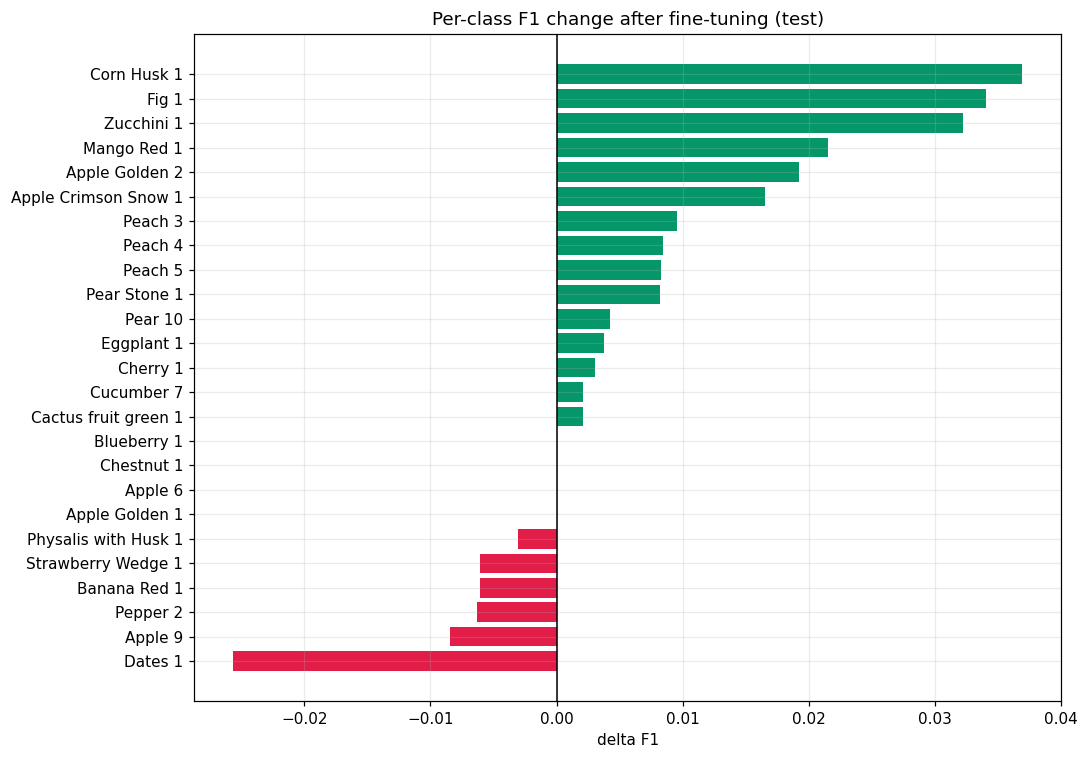

Weakest classes after fine-tuning:


,precision,recall,f1-score,support
Corn Husk 1,1.000,0.760,0.863,154.0
Eggplant 1,1.000,0.853,0.920,156.0
Dates 1,0.922,1.000,0.960,166.0
Pear Stone 1,0.963,1.000,0.981,237.0
Cactus fruit green 1,0.967,1.000,0.983,231.0
Apple 9,0.967,1.000,0.983,231.0
Apple Golden 2,1.000,0.970,0.985,164.0
Fig 1,0.971,1.000,0.985,234.0
Cucumber 7,0.983,1.000,0.992,234.0
Peach 3,0.984,1.000,0.992,306.0


In [22]:
y_true = after["test"]["y_true"]
labels = np.arange(NUM_CLASSES)

rep_before = pd.DataFrame(classification_report(
    y_true, before["test"]["y_pred"], labels=labels, target_names=CLASSES,
    output_dict=True, zero_division=0)).T
rep_after = pd.DataFrame(classification_report(
    y_true, after["test"]["y_pred"], labels=labels, target_names=CLASSES,
    output_dict=True, zero_division=0)).T
rep_before.to_csv(ARTIFACTS / "classification_report_before.csv")
rep_after.to_csv(ARTIFACTS / "classification_report_after.csv")

delta = (rep_after["f1-score"] - rep_before["f1-score"]).loc[CLASSES].sort_values()
changed = delta if NUM_CLASSES <= 40 else pd.concat([delta.head(10), delta.tail(15)])

fig, ax = plt.subplots(figsize=(10, max(7, 0.28 * len(changed))))
ax.barh(changed.index, changed.values, color=np.where(changed.values >= 0, "#059669", "#e11d48"))
ax.axvline(0, color="black", linewidth=1)
ax.set(title="Per-class F1 change after fine-tuning (test)", xlabel="delta F1")
plt.tight_layout()
plt.show()

print("Weakest classes after fine-tuning:")
rep_after.loc[CLASSES].sort_values("f1-score").head(15)[["precision", "recall", "f1-score", "support"]].round(3)

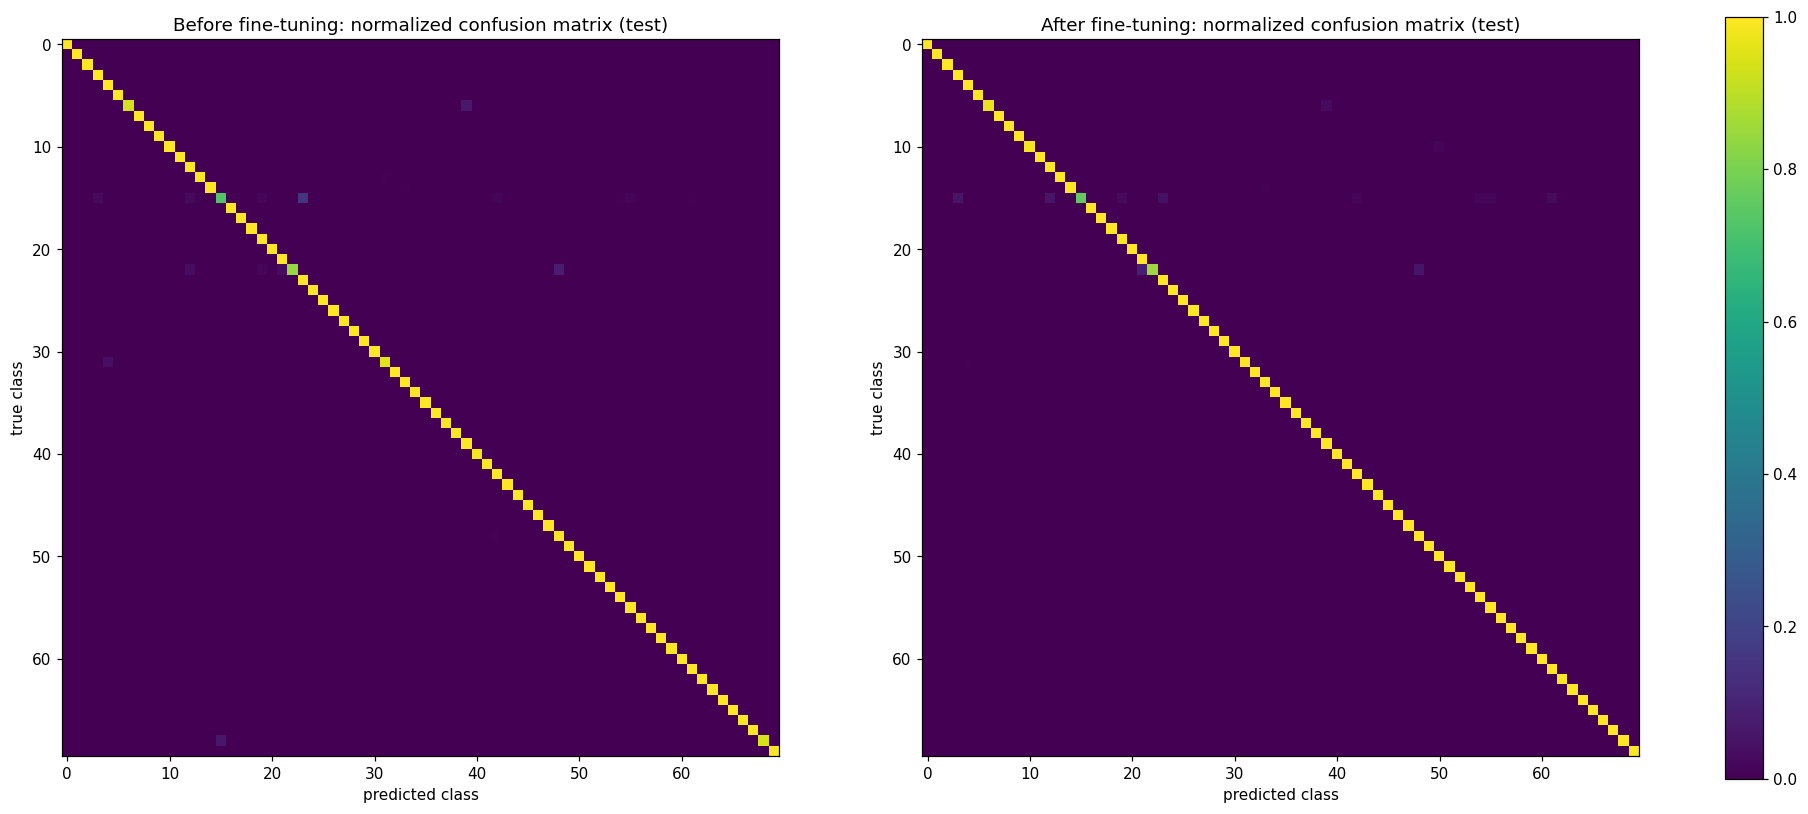

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(20, 9))
for ax, (title, res) in zip(axes, (("Before fine-tuning", before), ("After fine-tuning", after))):
    cm = confusion_matrix(y_true, res["test"]["y_pred"], labels=labels, normalize="true")
    im = ax.imshow(cm, cmap="viridis", vmin=0, vmax=1)
    ax.set(title=f"{title}: normalized confusion matrix (test)", xlabel="predicted class", ylabel="true class")
    if NUM_CLASSES <= 40:
        ax.set_xticks(labels)
        ax.set_xticklabels(CLASSES, rotation=90, fontsize=7)
        ax.set_yticks(labels)
        ax.set_yticklabels(CLASSES, fontsize=7)
    ax.grid(False)
fig.colorbar(im, ax=axes, fraction=0.025)
plt.show()

**Written assessment of metrics:** which classes are handled well, which are weak, and why.

## 10. Error analysis

In [24]:
def top_confusions(y_true, y_pred, k=15):
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    np.fill_diagonal(cm, 0)
    flat = np.argsort(cm.ravel())[::-1][:k]
    rows = [(CLASSES[i], CLASSES[j], int(cm[i, j])) for i, j in zip(*np.unravel_index(flat, cm.shape)) if cm[i, j] > 0]
    return pd.DataFrame(rows, columns=["true", "predicted", "count"])


top_confusions(y_true, after["test"]["y_pred"])

,true,predicted,count
0,Eggplant 1,Dates 1,14
1,Eggplant 1,Pear Stone 1,9
2,Corn Husk 1,Apple 9,8
3,Corn Husk 1,Cactus fruit green 1,8
4,Corn Husk 1,Fig 1,7
5,Apple Golden 2,Peach 3,5
6,Corn Husk 1,Strawberry Wedge 1,4
7,Corn Husk 1,Cucumber 7,4
8,Banana Red 1,Pepper 2,2
9,Corn Husk 1,Pear 10,2


misclassified: 69 of 12703 (0.54%)


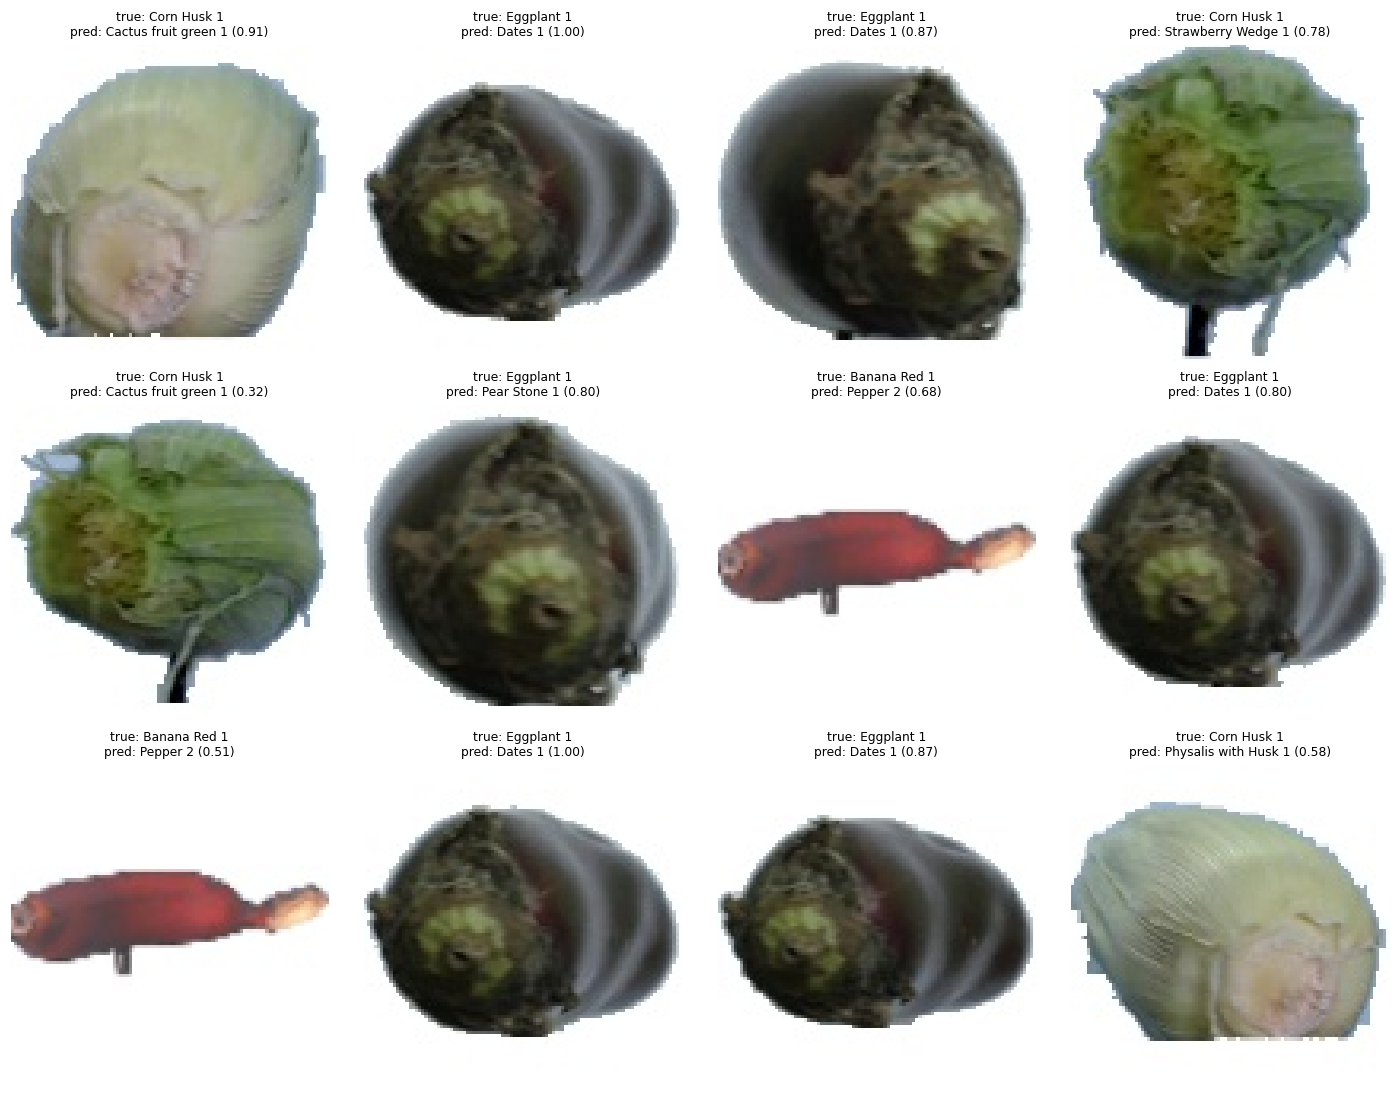

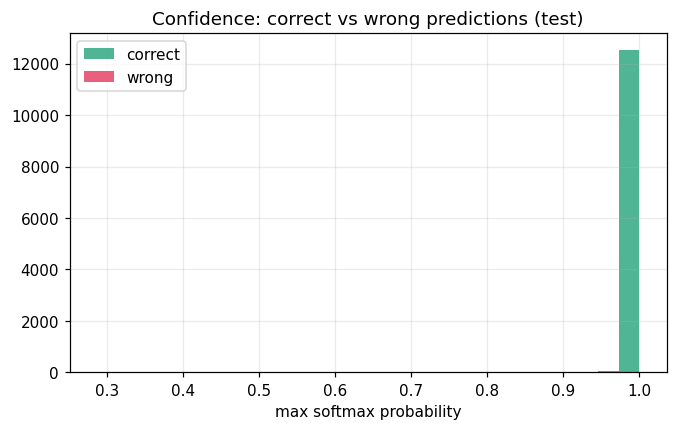

In [25]:
y_pred = after["test"]["y_pred"]
conf = after["test"]["probs"].max(1)
wrong = np.where(y_true != y_pred)[0]
print(f"misclassified: {len(wrong)} of {len(y_true)} ({len(wrong) / len(y_true):.2%})")

if len(wrong):
    picks = np.random.default_rng(SEED).choice(wrong, size=min(12, len(wrong)), replace=False)
    fig, axes = plt.subplots(3, 4, figsize=(13, 10))
    for ax in axes.ravel():
        ax.axis("off")
    for ax, i in zip(axes.ravel(), picks):
        ax.imshow(Image.open(test_df.loc[i, "path"]))
        ax.set_title(f"true: {CLASSES[y_true[i]]}\npred: {CLASSES[y_pred[i]]} ({conf[i]:.2f})", fontsize=8)
    plt.tight_layout()
    plt.show()

    fig, ax = plt.subplots(figsize=(7, 4))
    ax.hist(conf[y_true == y_pred], bins=20, alpha=0.7, label="correct", color="#059669")
    ax.hist(conf[wrong], bins=20, alpha=0.7, label="wrong", color="#e11d48")
    ax.set(title="Confidence: correct vs wrong predictions (test)", xlabel="max softmax probability")
    ax.legend()
    plt.show()

**Observation:** causes of failure (similar-looking classes, image quality, imbalance, background) and the evidence for each.

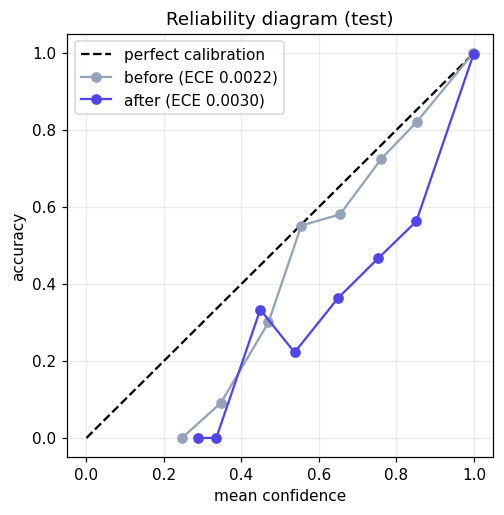

In [26]:
def reliability(y_true, probs, bins=10):
    conf = probs.max(1)
    correct = probs.argmax(1) == y_true
    edges = np.linspace(0, 1, bins + 1)
    ece, xs, ys = 0.0, [], []
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any():
            ece += m.mean() * abs(correct[m].mean() - conf[m].mean())
            xs.append(conf[m].mean())
            ys.append(correct[m].mean())
    return ece, xs, ys


fig, ax = plt.subplots(figsize=(5, 5))
ax.plot([0, 1], [0, 1], "k--", label="perfect calibration")
for label, res, color in (("before", before, "#94a3b8"), ("after", after, "#4f46e5")):
    ece, xs, ys = reliability(res["test"]["y_true"], res["test"]["probs"])
    ax.plot(xs, ys, marker="o", color=color, label=f"{label} (ECE {ece:.4f})")
ax.set(title="Reliability diagram (test)", xlabel="mean confidence", ylabel="accuracy")
ax.legend()
plt.show()

## 11. Save artifacts

In [27]:
keras.mixed_precision.set_global_policy("float32")
keras.backend.clear_session()
export_model, _ = build(BEST)
export_model.load_weights(str(ARTIFACTS / f"{BEST}_ft.weights.h5"))
export_model.save(ARTIFACTS / "fruit_model.keras")
(ARTIFACTS / "class_names.json").write_text(json.dumps(CLASSES))
(ARTIFACTS / "config.json").write_text(json.dumps({
    "backbone": BEST,
    "img_size": IMG_SIZE,
    "test_accuracy": float(table.loc["accuracy", "test_after"]),
    "test_macro_f1": float(table.loc["f1", "test_after"]),
}, indent=2))
table.round(5).to_csv(ARTIFACTS / "metrics_before_after.csv")
comparison.round(5).to_csv(ARTIFACTS / "model_comparison.csv")
(ARTIFACTS / "dataset_card.json").write_text(json.dumps(dataset_card, indent=2))

pins = []
for pkg in ["tensorflow", "numpy", "pandas", "pillow", "matplotlib", "scikit-learn", "streamlit", "kagglehub"]:
    try:
        pins.append(f"{pkg}=={version(pkg)}")
    except Exception:
        pins.append(pkg)
Path("requirements.txt").write_text("\n".join(pins) + "\n")
print("\n".join(pins))

tensorflow==2.20.0
numpy==2.1.3
pandas==2.3.3
pillow==12.3.0
matplotlib==3.10.0
scikit-learn==1.6.1
streamlit
kagglehub==1.0.2


## 12. Streamlit app

In [28]:
APP_CODE = r"""
import json
from pathlib import Path

import numpy as np
import pandas as pd
import streamlit as st
import tensorflow as tf
from PIL import Image
from tensorflow import keras
from tensorflow.keras.applications import efficientnet, mobilenet_v2, resnet50

ARTIFACTS = Path(__file__).parent / "artifacts"

PREPROCESS = {
    "mobilenetv2": mobilenet_v2.preprocess_input,
    "resnet50": resnet50.preprocess_input,
    "efficientnetb0": efficientnet.preprocess_input,
    "custom_cnn": lambda x: x / 255.0,
}

st.set_page_config(page_title="Fruit Classifier", page_icon="🍎")


@st.cache_resource
def load_assets():
    model = keras.models.load_model(ARTIFACTS / "fruit_model.keras")
    class_names = json.loads((ARTIFACTS / "class_names.json").read_text())
    config = json.loads((ARTIFACTS / "config.json").read_text())
    return model, class_names, config


model, class_names, config = load_assets()
size = config["img_size"]
preprocess = PREPROCESS[config["backbone"]]

st.title("🍎 Fruit Classifier")
st.caption(f"Backbone: {config['backbone']} | Test accuracy: {config['test_accuracy']:.2%} | Classes: {len(class_names)}")

threshold = st.sidebar.slider("Confidence threshold", 0.0, 1.0, 0.5, 0.05)
st.sidebar.info("Trained on Fruits-360 (single fruit on a white background). Cluttered real-world photos may be misclassified.")

file = st.file_uploader("Upload a fruit image", type=["jpg", "jpeg", "png"])

if file:
    image = Image.open(file).convert("RGB")
    arr = tf.cast(tf.round(tf.image.resize(np.asarray(image, dtype=np.float32), (size, size))), tf.float32).numpy()
    probs = model.predict(preprocess(arr)[None], verbose=0)[0]
    top = probs.argsort()[::-1][:3]
    best, conf = int(top[0]), float(probs[top[0]])

    left, right = st.columns(2)
    left.image(image, caption="Uploaded image", use_container_width=True)
    with right:
        if conf >= threshold:
            st.success(f"Prediction: {class_names[best]}")
        else:
            st.warning(f"Uncertain. Closest match: {class_names[best]}")
        st.metric("Confidence", f"{conf:.1%}")
        st.progress(min(conf, 1.0))

    chart = pd.DataFrame({
        "class": [class_names[i] for i in top],
        "confidence": [float(probs[i]) for i in top],
    }).set_index("class")
    st.subheader("Top-3 predictions")
    st.bar_chart(chart)
"""
Path("app.py").write_text(APP_CODE.lstrip())

2332

Run the app from the folder that contains `app.py` and `artifacts/`:

```bash
pip install -r requirements.txt
streamlit run app.py
```

If the notebook ran on Kaggle or Colab, download `app.py`, `requirements.txt` and the `artifacts/` folder first, then run the app on your own machine.